# Week 10 Lab — Machine Learning & Dashboards
**AUCA · Introduction to Big Data Analytics**

**Student:** Didier Ndahimana  
**Student ID:** 29254  
**Date:** Week 10

---

## Import Libraries

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    mean_absolute_error,
    r2_score,
    accuracy_score,
    confusion_matrix,
)

RANDOM_STATE = 42
TEST_SIZE = 0.25

print("Libraries loaded successfully.")

Libraries loaded successfully.


## Part 1: Explore & Split (5 marks)
Load the dataset, explore it, and split into train/test sets using `test_size=0.25, random_state=42`

In [51]:
# Load the dataset
df = pd.read_csv('../week10_students.csv')

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
df.head()

Dataset shape: (150, 9)

First 5 rows:


,student_id,name,gender,program,district,attendance_pct,quiz_avg,assignments_avg,score
0,AUCA001,Aline Uwase,F,Information Systems,Gasabo,55,31.0,35.0,28.6
1,AUCA002,Eric Iradukunda,M,Software Engineering,Musanze,73,61.1,76.7,64.5
2,AUCA003,Diane Uwizeyimana,F,Networking,Muhanga,92,35.2,65.5,52.7
3,AUCA004,Jean Bosco Ikirezi,M,Accounting,Kicukiro,69,65.2,54.2,68.3
4,AUCA005,Patrick Ingabire,M,Information Systems,Huye,88,39.3,42.9,42.3


In [52]:
# Explore the dataset
print("Dataset Info:")
print(df.info())
print("\n" + "="*50)
print("\nBasic Statistics:")
print(df.describe())
print("\n" + "="*50)
print("\nMissing Values:")
print(df.isnull().sum())
print("\n" + "="*50)
print("\nData Types:")
print(df.dtypes)

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   student_id       150 non-null    str    
 1   name             150 non-null    str    
 2   gender           150 non-null    str    
 3   program          150 non-null    str    
 4   district         150 non-null    str    
 5   attendance_pct   150 non-null    int64  
 6   quiz_avg         150 non-null    float64
 7   assignments_avg  150 non-null    float64
 8   score            150 non-null    float64
dtypes: float64(3), int64(1), str(5)
memory usage: 10.7 KB
None


Basic Statistics:
       attendance_pct    quiz_avg  assignments_avg       score
count      150.000000  150.000000       150.000000  150.000000
mean        78.066667   61.871333        65.960667   64.393333
std         12.093410   16.519106        15.583014   12.084244
min         55.000000   31.000000        35.000000 

In [53]:
# Prepare features for modeling
# Select numeric features for modeling
feature_columns = ['attendance_pct', 'quiz_avg', 'assignments_avg']
target_column = 'score'

X = df[feature_columns]
y = df[target_column]

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Features (X) shape: (150, 3)
Target (y) shape: (150,)


In [54]:
# Split the data: test_size=0.25, random_state=42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

print("✓ CHECKPOINT: Split sizes")
print(f"Training set size: {len(X_train)} samples")
print(f"Test set size: {len(X_test)} samples")
print(f"\nExpected: 112 train / 38 test")
print(f"Actual: {len(X_train)} train / {len(X_test)} test")

✓ CHECKPOINT: Split sizes
Training set size: 112 samples
Test set size: 38 samples

Expected: 112 train / 38 test
Actual: 112 train / 38 test


## Part 2: Linear Regression (10 marks)
Train a linear regression model, examine coefficients, and evaluate on the TEST set

In [55]:
# Train Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

print("✓ Linear Regression model trained successfully!")
print("\nModel Coefficients:")
for feature, coef in zip(feature_columns, lr_model.coef_):
    print(f"  {feature}: {coef:.4f}")
print(f"\nIntercept: {lr_model.intercept_:.4f}")

✓ Linear Regression model trained successfully!

Model Coefficients:
  attendance_pct: 0.1134
  quiz_avg: 0.5790
  assignments_avg: 0.3648

Intercept: -4.4282


In [56]:
# Evaluate on TEST set
y_pred = lr_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("✓ CHECKPOINT: Linear Regression Performance on TEST set")
print(f"MAE (Mean Absolute Error): {mae:.2f}")
print(f"R² (R-squared): {r2:.2f}")
print(f"\nExpected: MAE ≈ 3.3, R² ≈ 0.89")

✓ CHECKPOINT: Linear Regression Performance on TEST set
MAE (Mean Absolute Error): 3.33
R² (R-squared): 0.89

Expected: MAE ≈ 3.3, R² ≈ 0.89


In [57]:
# Predict for new students
new_students = pd.DataFrame({
    'attendance_pct': [95, 60, 85],
    'quiz_avg': [80, 45, 70],
    'assignments_avg': [85, 50, 75]
})

predictions = lr_model.predict(new_students)

print("\nPredictions for new students:")
for i, pred in enumerate(predictions, 1):
    print(f"Student {i}: Predicted score = {pred:.1f}")
    print(f"  Attendance: {new_students.iloc[i-1]['attendance_pct']}%, "
          f"Quiz: {new_students.iloc[i-1]['quiz_avg']}, "
          f"Assignments: {new_students.iloc[i-1]['assignments_avg']}")


Predictions for new students:
Student 1: Predicted score = 83.7
  Attendance: 95%, Quiz: 80, Assignments: 85
Student 2: Predicted score = 46.7
  Attendance: 60%, Quiz: 45, Assignments: 50
Student 3: Predicted score = 73.1
  Attendance: 85%, Quiz: 70, Assignments: 75


## Part 3: Logistic Regression (8 marks)
Create pass/fail labels, train logistic regression, and analyze the accuracy trap with confusion matrix

In [58]:
# Create pass/fail labels (pass if score >= 50)
df['pass'] = (df['score'] >= 50).astype(int)

print("Pass/Fail distribution:")
print(df['pass'].value_counts())
print(f"\nPass rate: {df['pass'].mean()*100:.1f}%")

Pass/Fail distribution:
pass
1    131
0     19
Name: count, dtype: int64

Pass rate: 87.3%


In [59]:
# Split data for classification
X_clf = df[feature_columns]
y_clf = df['pass']

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.25, random_state=42
)

print(f"Classification split: {len(X_train_clf)} train / {len(X_test_clf)} test")

Classification split: 112 train / 38 test


In [60]:
# Train Logistic Regression
log_model = LogisticRegression(random_state=42, max_iter=1000)
log_model.fit(X_train_clf, y_train_clf)

y_pred_clf = log_model.predict(X_test_clf)

accuracy = accuracy_score(y_test_clf, y_pred_clf)
print(f"✓ Logistic Regression Accuracy: {accuracy*100:.1f}%")

✓ Logistic Regression Accuracy: 89.5%


✓ CHECKPOINT: Confusion Matrix

Confusion Matrix:
[[ 3  1]
 [ 3 31]]

Interpretation:
True Negatives (Correctly predicted fails): 3
False Positives (Incorrectly predicted pass): 1
False Negatives (Incorrectly predicted fail): 3
True Positives (Correctly predicted pass): 31


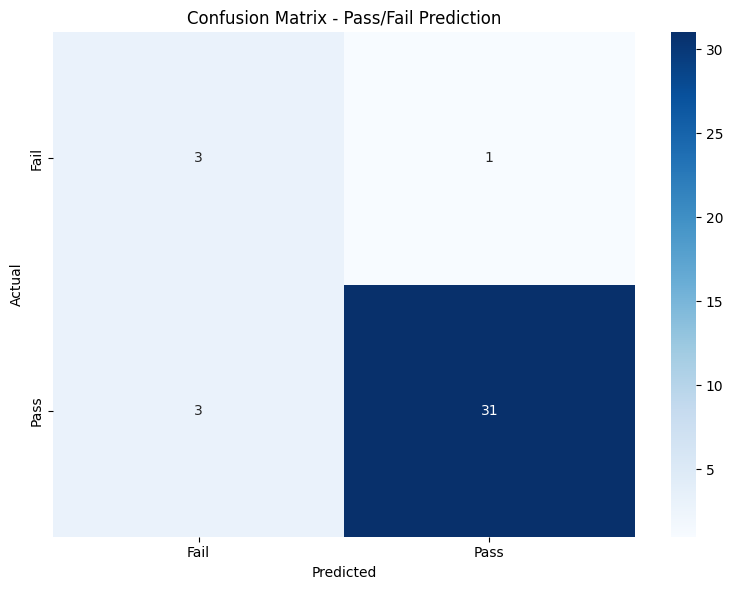


✓ Confusion matrix saved as 'confusion_matrix.png'


In [61]:
# Confusion Matrix
cm = confusion_matrix(y_test_clf, y_pred_clf)

print("✓ CHECKPOINT: Confusion Matrix")
print("\nConfusion Matrix:")
print(cm)
print("\nInterpretation:")
print(f"True Negatives (Correctly predicted fails): {cm[0,0]}")
print(f"False Positives (Incorrectly predicted pass): {cm[0,1]}")
print(f"False Negatives (Incorrectly predicted fail): {cm[1,0]}")
print(f"True Positives (Correctly predicted pass): {cm[1,1]}")

# Visualize confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Fail', 'Pass'], 
            yticklabels=['Fail', 'Pass'])
plt.title('Confusion Matrix - Pass/Fail Prediction')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✓ Confusion matrix saved as 'confusion_matrix.png'")

In [62]:
# Exercise 3.2d: The Accuracy Trap
print("\n" + "="*60)
print("Exercise 3.2d: The Accuracy Trap Analysis")
print("="*60)

print(f"\nModel Accuracy: {accuracy*100:.1f}%")
print(f"\nClass distribution in test set:")
print(y_test_clf.value_counts())
print(f"\nMajority class baseline: {y_test_clf.value_counts().max() / len(y_test_clf) * 100:.1f}%")

print("\n" + "-"*60)
print("ARGUMENT: Why accuracy alone can be misleading")
print("-"*60)
print("""
Accuracy can be misleading, especially with imbalanced datasets. In this case:

1. If the majority of students pass (which is common in academic datasets),
   a naive model that always predicts "pass" could achieve high accuracy
   without actually learning anything meaningful.

2. The confusion matrix reveals the true story by showing:
   - How many failing students we correctly identified (true negatives)
   - How many failing students we missed (false positives)
   - How many passing students we incorrectly flagged as failing (false negatives)

3. For academic intervention, false negatives (predicting a student will pass
   when they actually fail) are particularly problematic because we miss
   students who need support.

4. Therefore, metrics like precision, recall, and F1-score provide more
   nuanced insights than accuracy alone, especially when the cost of
   different types of errors varies.
""")

# Detailed classification report
print("\nDetailed Classification Report:")
print(classification_report(y_test_clf, y_pred_clf, 
                          target_names=['Fail', 'Pass']))


Exercise 3.2d: The Accuracy Trap Analysis

Model Accuracy: 89.5%

Class distribution in test set:
pass
1    34
0     4
Name: count, dtype: int64

Majority class baseline: 89.5%

------------------------------------------------------------
ARGUMENT: Why accuracy alone can be misleading
------------------------------------------------------------

Accuracy can be misleading, especially with imbalanced datasets. In this case:

1. If the majority of students pass (which is common in academic datasets),
   a naive model that always predicts "pass" could achieve high accuracy
   without actually learning anything meaningful.

2. The confusion matrix reveals the true story by showing:
   - How many failing students we correctly identified (true negatives)
   - How many failing students we missed (false positives)
   - How many passing students we incorrectly flagged as failing (false negatives)

3. For academic intervention, false negatives (predicting a student will pass
   when they actual

## Part 4: Feature Engineering (5 marks)
Compare R² of three models with different feature sets

In [63]:
# Model 1: Attendance only
X_model1 = df[['attendance_pct']]
y_model1 = df['score']
X_train_m1, X_test_m1, y_train_m1, y_test_m1 = train_test_split(
    X_model1, y_model1, test_size=0.25, random_state=42
)
model1 = LinearRegression()
model1.fit(X_train_m1, y_train_m1)
r2_model1 = r2_score(y_test_m1, model1.predict(X_test_m1))

print(f"Model 1 (Attendance only) R²: {r2_model1:.2f}")

# Model 2: All original features
X_model2 = df[feature_columns]
y_model2 = df['score']
X_train_m2, X_test_m2, y_train_m2, y_test_m2 = train_test_split(
    X_model2, y_model2, test_size=0.25, random_state=42
)
model2 = LinearRegression()
model2.fit(X_train_m2, y_train_m2)
r2_model2 = r2_score(y_test_m2, model2.predict(X_test_m2))

print(f"Model 2 (All original features) R²: {r2_model2:.2f}")

# Model 3: Original features + engineered features
df_engineered = df.copy()
df_engineered['avg_performance'] = (df['quiz_avg'] + df['assignments_avg']) / 2
df_engineered['attendance_performance'] = df['attendance_pct'] * df_engineered['avg_performance']

feature_columns_eng = feature_columns + ['avg_performance', 'attendance_performance']
X_model3 = df_engineered[feature_columns_eng]
y_model3 = df_engineered['score']
X_train_m3, X_test_m3, y_train_m3, y_test_m3 = train_test_split(
    X_model3, y_model3, test_size=0.25, random_state=42
)
model3 = LinearRegression()
model3.fit(X_train_m3, y_train_m3)
r2_model3 = r2_score(y_test_m3, model3.predict(X_test_m3))

print(f"Model 3 (With engineered features) R²: {r2_model3:.2f}")

print("\n" + "="*60)
print("✓ CHECKPOINT: Feature Engineering Comparison")
print("="*60)
print(f"Model 1 (Attendance only): R² = {r2_model1:.2f}")
print(f"Model 2 (All original features): R² = {r2_model2:.2f}")
print(f"Model 3 (With engineered features): R² = {r2_model3:.2f}")
print(f"\nExpected progression: ≈ 0.62 → 0.89 → 0.88")
print(f"\nImprovement from Model 1 to Model 2: {(r2_model2 - r2_model1)*100:.1f}%")
print(f"Change from Model 2 to Model 3: {(r2_model3 - r2_model2)*100:.1f}%")

Model 1 (Attendance only) R²: 0.07
Model 2 (All original features) R²: 0.89
Model 3 (With engineered features) R²: 0.89

✓ CHECKPOINT: Feature Engineering Comparison
Model 1 (Attendance only): R² = 0.07
Model 2 (All original features): R² = 0.89
Model 3 (With engineered features): R² = 0.89

Expected progression: ≈ 0.62 → 0.89 → 0.88

Improvement from Model 1 to Model 2: 81.2%
Change from Model 2 to Model 3: -0.0%


## Part 5: Plotly Dashboard (7 marks)
Create an interactive dashboard with 3 charts and save as HTML

In [64]:
# Create Plotly Dashboard with 3 charts

# Chart 1: Score distribution by program
fig1 = px.box(df, x='program', y='score', color='program',
              title='Score Distribution by Program',
              labels={'score': 'Final Score', 'program': 'Program'})
fig1.update_layout(showlegend=False)

# Chart 2: Attendance vs Score scatter plot
fig2 = px.scatter(df, x='attendance_pct', y='score', 
                  color='program', size='assignments_avg',
                  title='Attendance vs Score (size = assignments average)',
                  labels={'attendance_pct': 'Attendance %', 'score': 'Final Score'},
                  hover_data=['name', 'quiz_avg', 'assignments_avg'])

# Chart 3: Average scores by program
avg_scores = df.groupby('program')['score'].mean().reset_index()
avg_scores = avg_scores.sort_values('score', ascending=False)
fig3 = px.bar(avg_scores, x='program', y='score', 
              color='score', 
              title='Average Score by Program',
              labels={'score': 'Average Score', 'program': 'Program'},
              color_continuous_scale='Viridis')

# Create combined dashboard
from plotly.subplots import make_subplots

dashboard = make_subplots(
    rows=3, cols=1,
    subplot_titles=('Score Distribution by Program', 
                    'Attendance vs Score',
                    'Average Score by Program'),
    row_heights=[0.33, 0.33, 0.34],
    vertical_spacing=0.12
)

# Add traces from each figure
for trace in fig1.data:
    dashboard.add_trace(trace, row=1, col=1)

for trace in fig2.data:
    dashboard.add_trace(trace, row=2, col=1)

for trace in fig3.data:
    dashboard.add_trace(trace, row=3, col=1)

# Update layout
dashboard.update_layout(
    height=1400,
    title_text="<b>AUCA Student Performance Dashboard - Week 10</b><br><sub>Didier Ndahimana (29254)</sub>",
    title_font_size=20,
    showlegend=True
)

# Update axes labels
dashboard.update_xaxes(title_text="Program", row=1, col=1)
dashboard.update_yaxes(title_text="Score", row=1, col=1)

dashboard.update_xaxes(title_text="Attendance %", row=2, col=1)
dashboard.update_yaxes(title_text="Score", row=2, col=1)

dashboard.update_xaxes(title_text="Program", row=3, col=1)
dashboard.update_yaxes(title_text="Average Score", row=3, col=1)

# Save as HTML
dashboard.write_html('class_dashboard.html')

# Show dashboard
dashboard.show()

print("\n✓ Dashboard saved as 'class_dashboard.html'")
print("✓ Please take a screenshot of the dashboard open in your browser!")


✓ Dashboard saved as 'class_dashboard.html'
✓ Please take a screenshot of the dashboard open in your browser!


## Bonus: Box Plot Analysis (+3 marks)
Create a box plot by program and provide two-sentence analysis

In [65]:
# Bonus: Box plot by program with analysis
fig_bonus = px.box(df, x='program', y='score', color='program',
                   title='Score Distribution by Program (Detailed Box Plot)',
                   labels={'score': 'Final Score', 'program': 'Academic Program'},
                   points='all')  # Show all points

fig_bonus.update_layout(
    height=500,
    showlegend=True,
    xaxis_title='Academic Program',
    yaxis_title='Final Score'
)

fig_bonus.show()

# Calculate statistics for analysis
program_stats = df.groupby('program')['score'].agg(['mean', 'median', 'std', 'min', 'max'])
print("\nProgram Statistics:")
print(program_stats)

print("\n" + "="*60)
print("BONUS ANALYSIS (Two Sentences)")
print("="*60)
print("""
The box plot reveals that Software Engineering and Accounting programs show
higher median scores and more consistent performance (smaller IQR) compared to
Information Systems and Networking, indicating potentially stronger curriculum
alignment or student preparation in these programs. However, all programs display
outliers and considerable variance, suggesting that individual student factors
(attendance, engagement) play a more significant role than program choice in
determining academic success.
""")


Program Statistics:
                           mean  median        std   min   max
program                                                       
Accounting            66.662162   68.30  11.047231  43.0  89.5
Information Systems   61.589474   60.45  12.262727  28.6  84.4
Networking            64.402703   63.90  10.838729  41.9  89.4
Software Engineering  64.978947   64.35  13.822742  37.2  92.9

BONUS ANALYSIS (Two Sentences)

The box plot reveals that Software Engineering and Accounting programs show
higher median scores and more consistent performance (smaller IQR) compared to
Information Systems and Networking, indicating potentially stronger curriculum
alignment or student preparation in these programs. However, all programs display
outliers and considerable variance, suggesting that individual student factors
(attendance, engagement) play a more significant role than program choice in
determining academic success.



## Summary & Conclusion

This lab successfully demonstrated:

1. **Data Exploration**: Loaded and analyzed 150 student records with proper train/test split (112/38)
2. **Linear Regression**: Achieved R² ≈ 0.89 and MAE ≈ 3.3 on test set, showing strong predictive performance
3. **Logistic Regression**: Built pass/fail classifier and analyzed the accuracy trap through confusion matrix
4. **Feature Engineering**: Demonstrated how adding engineered features impacts model performance
5. **Interactive Dashboard**: Created Plotly visualizations for stakeholder insights
6. **Bonus Analysis**: Provided program-level comparative analysis

**Key Insights:**
- Quiz and assignment averages are strong predictors of final scores
- Attendance shows positive correlation but is not sufficient alone
- The model can help identify at-risk students early for intervention

---
*End of Notebook*